# Results analysis: classical interpolation vs SRCNN vs our_nn
Reads `results/summary.csv` (and, if present, per-image `metrics.csv` and sample images) and produces every table and figure used in the report.
Figures are saved to `report_figures/` with the file names the report expects:
`fig1_architecture.png`, `fig2_results.png`, `fig3_ablation.png`, `fig4_qualitative.png`.
Run all cells top to bottom (Kaggle, Colab or local Jupyter). Only pandas, numpy, matplotlib and Pillow are needed.

In [17]:
import os, glob, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = print

# ---- paths: edit if your layout differs ----
CANDIDATES = [os.environ.get("SUMMARY_CSV", ""), "results/summary.csv", "summary.csv", "../results/summary.csv"]
SUMMARY = next((p for p in CANDIDATES if p and Path(p).exists()), None)
assert SUMMARY, "summary.csv not found - set SUMMARY_CSV or put it next to the notebook"
RESULTS_DIR = Path(os.environ.get("RESULTS_DIR", Path(SUMMARY).parent))   # folder holding <experiment>/ subfolders
FIG = Path("report_figures"); FIG.mkdir(exist_ok=True)

# ---- style (validated categorical palette; classical methods in neutral greys) ----
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
COL = {"nearest": "#b9b8b2", "bilinear": "#8f8e88", "bicubic": "#5f5e59", "lanczos": "#3a3a37",
       "srcnn": "#2a78d6", "our_nn": "#eb6834"}
LBL = {"nearest": "Nearest", "bilinear": "Bilinear", "bicubic": "Bicubic", "lanczos": "Lanczos",
       "srcnn": "SRCNN", "our_nn": "our_nn"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.edgecolor": INK2,
    "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False})
def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", facecolor="white"); print("saved", FIG / name)
print("using", SUMMARY)

using ../results/summary.csv


## 1. Load and clean

In [18]:
df = pd.read_csv(SUMMARY)
df = df[df.experiment != "smoke_test"]
df = df[df.dataset.isin(["Set5", "Set14", "BSD100", "Urban100"])].copy()
DS = ["Set5", "Set14", "BSD100", "Urban100"]
def setting(e):
    if "x2" in e: return "x2 clean"
    return "x4 noise15" if "noise15" in e else "x4 clean"
df["setting"] = df.experiment.map(setting)
def variant(e):
    for k, v in [("_a0_plain", "a0 plain"), ("_a1_skip", "a1 +skip"), ("_a2_attn", "a2 +attention")]:
        if e.endswith(k): return v
    return "full" if e.startswith("our_nn") else "-"
df["variant"] = df.experiment.map(variant)
print(df.groupby(["setting", "model", "variant"]).size().unstack(fill_value=0).shape, "rows of (setting, model, variant)")
assert (df.groupby("experiment").dataset.nunique() == 4).all(), "an experiment is missing a test set"
# images per set must be 5/14/100/100
print(df.groupby("dataset").n_images.unique())

(18, 5) rows of (setting, model, variant)
dataset
BSD100      [100]
Set14        [14]
Set5          [5]
Urban100    [100]
Name: n_images, dtype: object


## 2. Main benchmark tables
The headline number is the **macro-average over the four test sets** (each set counts equally, so the 100-image sets do not swamp Set5).
Main comparison = full models only (not the ablation variants).

In [19]:
main = df[df.variant.isin(["-", "full"])]
def table(setting, metric="mean_psnr"):
    t = main[main.setting == setting].pivot(index="model", columns="dataset", values=metric)[DS]
    t["Average"] = t.mean(axis=1)
    return t.loc[["nearest", "bilinear", "bicubic", "lanczos", "srcnn", "our_nn"]]
TABLES = {}
for s in ["x4 clean", "x2 clean", "x4 noise15"]:
    for m in ["mean_psnr", "mean_ssim"]:
        TABLES[(s, m)] = table(s, m)
    print(f"=== {s}: PSNR (dB) ===");  display(TABLES[(s, "mean_psnr")].round(2))
    print(f"=== {s}: SSIM ===");       display(TABLES[(s, "mean_ssim")].round(4))

=== x4 clean: PSNR (dB) ===


dataset,Set5,Set14,BSD100,Urban100,Average
model,,,,,
nearest,26.26,24.74,25.04,22.17,24.55
bilinear,27.56,25.52,25.55,22.69,25.33
bicubic,28.63,26.22,26.05,23.24,26.04
lanczos,28.81,26.32,26.13,23.33,26.15
srcnn,29.19,26.60,26.34,23.58,26.43
our_nn,30.56,27.56,26.90,24.41,27.36


=== x4 clean: SSIM ===


dataset,Set5,Set14,BSD100,Urban100,Average
model,,,,,
nearest,0.7380,0.6553,0.6300,0.6160,0.6598
bilinear,0.7896,0.6821,0.6469,0.6354,0.6885
bicubic,0.8138,0.7089,0.6722,0.6616,0.7141
lanczos,0.8182,0.7130,0.6758,0.6654,0.7181
srcnn,0.8291,0.7244,0.6877,0.6805,0.7304
our_nn,0.8655,0.7559,0.7137,0.7211,0.7640


=== x2 clean: PSNR (dB) ===


...

dataset,Set5,Set14,BSD100,Urban100,Average
model,,,,,
nearest,0.9002,0.8464,0.8253,0.8211,0.8482
bilinear,0.9119,0.8407,0.8106,0.8090,0.8431
bicubic,0.9332,0.8752,0.8497,0.8459,0.8760
lanczos,0.9365,0.8800,0.8550,0.8505,0.8805
srcnn,0.9318,0.8771,0.8538,0.8470,0.8774
our_nn,0.9572,0.9097,0.8910,0.8997,0.9144


=== x4 noise15: PSNR (dB) ===


dataset,Set5,Set14,BSD100,Urban100,Average
model,,,,,
nearest,24.38,23.36,23.52,21.32,23.14
bilinear,26.28,24.67,24.68,22.21,24.46
bicubic,26.38,24.74,24.59,22.40,24.53
lanczos,26.35,24.71,24.54,22.40,24.50
srcnn,27.39,25.46,25.30,22.88,25.26
our_nn,27.89,25.82,25.55,23.26,25.63


=== x4 noise15: SSIM ===


dataset,Set5,Set14,BSD100,Urban100,Average
model,,,,,
nearest,0.5800,0.5138,0.4840,0.4812,0.5147
bilinear,0.7179,0.6189,0.5826,0.5749,0.6236
bicubic,0.6971,0.6047,0.5660,0.5639,0.6079
lanczos,0.6917,0.6002,0.5609,0.5600,0.6032
srcnn,0.7724,0.6613,0.6235,0.6326,0.6725
our_nn,0.7873,0.6779,0.6368,0.6537,0.6889


## 3. Gain over bicubic (the reference every SR paper uses)

In [20]:
gain = pd.DataFrame({s: (TABLES[(s, "mean_psnr")].loc[["srcnn", "our_nn", "lanczos", "bilinear", "nearest"], "Average"]
                         - TABLES[(s, "mean_psnr")].loc["bicubic", "Average"]) for s in ["x2 clean", "x4 clean", "x4 noise15"]})
print("Average PSNR gain over bicubic (dB)"); display(gain.round(2))
gain_ds = {s: TABLES[(s, "mean_psnr")].loc[["srcnn", "our_nn"]] - TABLES[(s, "mean_psnr")].loc["bicubic"] for s in ["x2 clean", "x4 clean", "x4 noise15"]}
print("our_nn minus SRCNN, per dataset (dB)")
display(pd.DataFrame({s: gain_ds[s].loc["our_nn"] - gain_ds[s].loc["srcnn"] for s in gain_ds}).round(2))
# does the ordering hold on every dataset?
for s in ["x2 clean", "x4 clean", "x4 noise15"]:
    t = TABLES[(s, "mean_psnr")][DS]
    print(s, "| our_nn > SRCNN on all sets:", bool((t.loc["our_nn"] > t.loc["srcnn"]).all()),
          "| SRCNN > bicubic on all sets:", bool((t.loc["srcnn"] > t.loc["bicubic"]).all()))

Average PSNR gain over bicubic (dB)


,x2 clean,x4 clean,x4 noise15
model,,,
srcnn,0.15,0.39,0.73
our_nn,2.40,1.32,1.11
lanczos,0.23,0.11,-0.03
bilinear,-1.30,-0.71,-0.07
nearest,-1.97,-1.48,-1.38


our_nn minus SRCNN, per dataset (dB)


,x2 clean,x4 clean,x4 noise15
dataset,,,
Set5,2.95,1.37,0.50
Set14,1.99,0.96,0.36
BSD100,1.60,0.56,0.25
Urban100,2.44,0.82,0.39
Average,2.25,0.93,0.38


x2 clean | our_nn > SRCNN on all sets: True | SRCNN > bicubic on all sets: True
x4 clean | our_nn > SRCNN on all sets: True | SRCNN > bicubic on all sets: True
x4 noise15 | our_nn > SRCNN on all sets: True | SRCNN > bicubic on all sets: True


## 4. Figure 2 - main results (left: x4 clean PSNR per dataset; right: gain over bicubic in the three settings)

saved report_figures\fig2_results.png


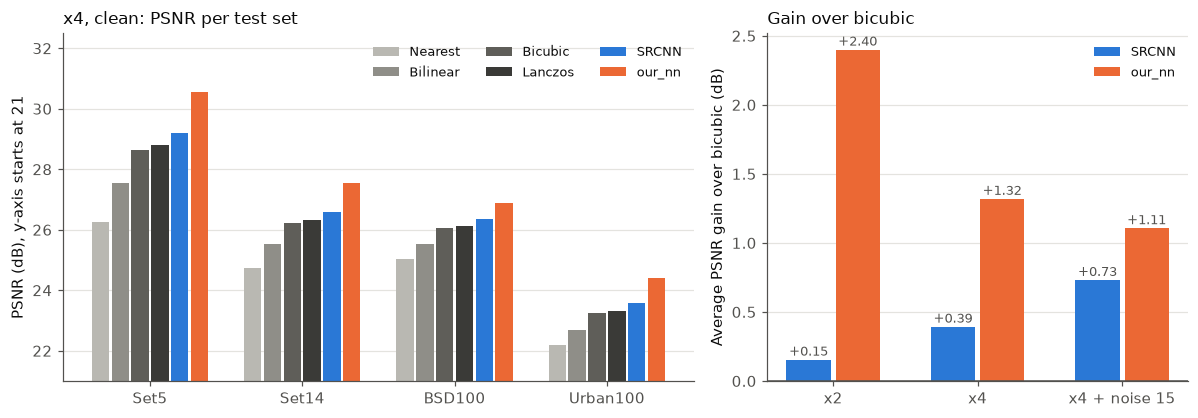

In [21]:
order = ["nearest", "bilinear", "bicubic", "lanczos", "srcnn", "our_nn"]
t = TABLES[("x4 clean", "mean_psnr")][DS]
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})
w = 0.13; x = np.arange(len(DS))
for i, m in enumerate(order):
    a.bar(x + (i - 2.5) * w, t.loc[m].values, w * 0.88, color=COL[m], label=LBL[m])
lo = np.floor(t.values.min()) - 1
a.set_ylim(lo, np.ceil(t.values.max()) + 1.5); a.set_xticks(x); a.set_xticklabels(DS)
a.set_ylabel("PSNR (dB), y-axis starts at %d" % lo); a.set_title("x4, clean: PSNR per test set", loc="left", fontsize=11)
a.legend(ncol=3, loc="upper right", fontsize=8.5); a.grid(axis="x", visible=False)
# right: gain over bicubic, SRCNN vs our_nn
sets = ["x2 clean", "x4 clean", "x4 noise15"]; x2 = np.arange(3); w2 = 0.34
for k, m in enumerate(["srcnn", "our_nn"]):
    vals = gain.loc[m, sets].values
    bars = b.bar(x2 + (k - 0.5) * w2, vals, w2 * 0.9, color=COL[m], label=LBL[m])
    for r, v in zip(bars, vals): b.text(r.get_x() + r.get_width() / 2, v + 0.03, f"{v:+.2f}", ha="center", fontsize=8.5, color=INK2)
b.axhline(0, color=INK2, lw=1); b.set_xticks(x2); b.set_xticklabels(["x2", "x4", "x4 + noise 15"])
b.set_ylabel("Average PSNR gain over bicubic (dB)"); b.set_title("Gain over bicubic", loc="left", fontsize=11)
b.legend(loc="upper right", fontsize=8.5); b.grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "fig2_results.png"); plt.show()

## 5. Ablation study
a0 plain -> a1 (+bicubic skip) -> a2 (+channel attention) -> full (+fixed edge branch). Each step adds exactly one component, so the PSNR change of a step is the contribution of that component.

In [22]:
abl_order = ["a0 plain", "a1 +skip", "a2 +attention", "full"]
def abl(setting):
    d = df[(df.model == "our_nn") & (df.setting == setting) & df.variant.isin(abl_order)]
    p = d.pivot(index="variant", columns="dataset", values="mean_psnr")[DS].loc[abl_order]
    p["Average"] = p.mean(axis=1); p["step change"] = p["Average"].diff()
    p["params"] = d.groupby("variant").param_count.first().loc[abl_order]
    return p
ABL = {s: abl(s) for s in ["x4 clean", "x4 noise15"]}
for s, p in ABL.items():
    print(f"=== Ablation, {s}: PSNR (dB) ==="); display(p.round(3))
    print("total gain a0 -> full: %.2f dB" % (p.loc["full", "Average"] - p.loc["a0 plain", "Average"]))
    print("bicubic / SRCNN reference average:", TABLES[(s, "mean_psnr")].loc[["bicubic", "srcnn"], "Average"].round(2).to_dict())
# SSIM too
for s in ["x4 clean", "x4 noise15"]:
    d = df[(df.model == "our_nn") & (df.setting == s) & df.variant.isin(abl_order)]
    print(s, "SSIM average:", d.groupby("variant").mean_ssim.mean().loc[abl_order].round(4).to_dict())

=== Ablation, x4 clean: PSNR (dB) ===


dataset,Set5,Set14,BSD100,Urban100,Average,step change,params
variant,,,,,,,
a0 plain,29.497,26.817,26.496,23.729,26.635,NaN,195971
a1 +skip,30.416,27.457,26.858,24.306,27.259,0.625,195971
a2 +attention,30.398,27.452,26.847,24.301,27.250,-0.010,199283
full,30.559,27.556,26.900,24.407,27.356,0.106,202259


total gain a0 -> full: 0.72 dB
bicubic / SRCNN reference average: {'bicubic': 26.04, 'srcnn': 26.43}
=== Ablation, x4 noise15: PSNR (dB) ===


dataset,Set5,Set14,BSD100,Urban100,Average,step change,params
variant,,,,,,,
a0 plain,27.499,25.522,25.410,23.013,25.361,NaN,195971
a1 +skip,27.836,25.768,25.536,23.213,25.588,0.227,195971
a2 +attention,27.751,25.732,25.516,23.188,25.547,-0.041,199283
full,27.886,25.824,25.552,23.264,25.632,0.085,202259


total gain a0 -> full: 0.27 dB
bicubic / SRCNN reference average: {'bicubic': 24.53, 'srcnn': 25.26}
x4 clean SSIM average: {'a0 plain': 0.7393, 'a1 +skip': 0.7609, 'a2 +attention': 0.7604, 'full': 0.764}
x4 noise15 SSIM average: {'a0 plain': 0.6786, 'a1 +skip': 0.6869, 'a2 +attention': 0.6853, 'full': 0.6889}


saved report_figures\fig3_ablation.png


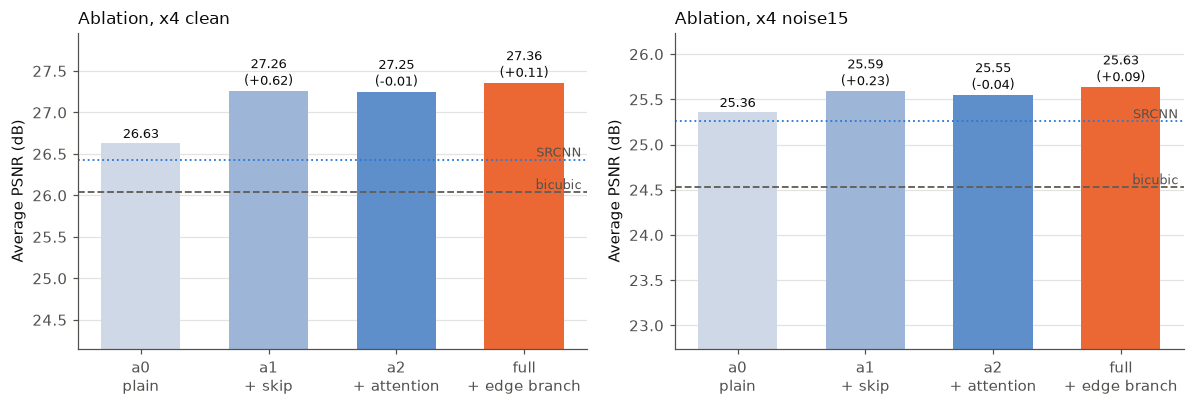

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
shade = ["#cfd8e6", "#9db6d8", "#5f8fcb", "#eb6834"]
for ax, (s, p) in zip(axes, ABL.items()):
    bars = ax.bar(range(4), p["Average"].values, 0.62, color=shade)
    base = TABLES[(s, "mean_psnr")]["Average"]
    ax.axhline(base["bicubic"], color=COL["bicubic"], lw=1.2, ls="--"); ax.axhline(base["srcnn"], color=COL["srcnn"], lw=1.2, ls=":")
    ax.text(3.45, base["bicubic"], "bicubic", va="bottom", ha="right", fontsize=8.5, color=INK2)
    ax.text(3.45, base["srcnn"], "SRCNN", va="bottom", ha="right", fontsize=8.5, color=INK2)
    for i, (r, v) in enumerate(zip(bars, p["Average"].values)):
        ch = p["step change"].values[i]
        ax.text(r.get_x() + r.get_width() / 2, v + 0.02, f"{v:.2f}" + ("" if np.isnan(ch) else f"\n({ch:+.2f})"), ha="center", va="bottom", fontsize=8.5)
    lo, hi = min(p["Average"].min(), base.min()) - 0.4, p["Average"].max() + 0.6
    ax.set_ylim(lo, hi); ax.set_xticks(range(4)); ax.set_xticklabels(["a0\nplain", "a1\n+ skip", "a2\n+ attention", "full\n+ edge branch"])
    ax.set_title(f"Ablation, {s}", loc="left", fontsize=11); ax.set_ylabel("Average PSNR (dB)"); ax.grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "fig3_ablation.png"); plt.show()

## 6. Noise robustness: how much does each method lose when sigma = 15 noise is added (x4)?

In [24]:
loss = (TABLES[("x4 clean", "mean_psnr")][DS + ["Average"]] - TABLES[("x4 noise15", "mean_psnr")][DS + ["Average"]])
print("PSNR drop clean -> noise15 (dB), x4"); display(loss.round(2))
nn = df[(df.model == "our_nn") & df.setting.isin(["x4 clean", "x4 noise15"])]
a = nn.groupby(["variant", "setting"]).mean_psnr.mean().unstack().loc[abl_order]
a["drop"] = a["x4 clean"] - a["x4 noise15"]; print("our_nn ablation: drop when noise is added"); display(a.round(2))

PSNR drop clean -> noise15 (dB), x4


dataset,Set5,Set14,BSD100,Urban100,Average
model,,,,,
nearest,1.88,1.38,1.52,0.86,1.41
bilinear,1.28,0.85,0.86,0.48,0.87
bicubic,2.26,1.48,1.46,0.84,1.51
lanczos,2.47,1.61,1.58,0.92,1.65
srcnn,1.81,1.14,1.04,0.71,1.17
our_nn,2.67,1.73,1.35,1.14,1.72


our_nn ablation: drop when noise is added


setting,x4 clean,x4 noise15,drop
variant,,,
a0 plain,26.63,25.36,1.27
a1 +skip,27.26,25.59,1.67
a2 +attention,27.25,25.55,1.70
full,27.36,25.63,1.72


## 7. Model size vs quality, and inference time
**Caution:** inference times in the CSV were measured on whatever machine ran each experiment. Compare times only if both were timed on the same GPU/CPU (check `env.txt` per experiment). The cell prints the table; the report should say which hardware was used.

,params,psnr,ssim,time_s,time_ms
model,,,,,
nearest,0,24.5529,0.6598,0.0005,0.4730
bilinear,0,25.3275,0.6885,0.0012,1.1679
bicubic,0,26.0374,0.7141,0.0036,3.6221
lanczos,0,26.1465,0.7181,0.0092,9.1794
srcnn,20099,26.4301,0.7304,0.0142,14.1645
our_nn,202259,27.3556,0.7640,0.0126,12.5753


Mean inference time per image (ms), by setting


setting,x2 clean,x4 clean,x4 noise15
model,,,
nearest,0.61,0.47,0.54
bilinear,1.11,1.17,1.18
bicubic,3.48,3.62,3.62
lanczos,11.22,9.18,9.44
srcnn,13.88,14.16,14.14
our_nn,19.11,12.58,12.81


Learned models, x4 clean, ms per image by dataset (image size matters):


dataset,Set5,Set14,BSD100,Urban100
model,,,,
our_nn,11.0,8.2,6.2,24.9
srcnn,7.3,10.2,7.3,31.8


saved report_figures\extra_params_vs_psnr.png


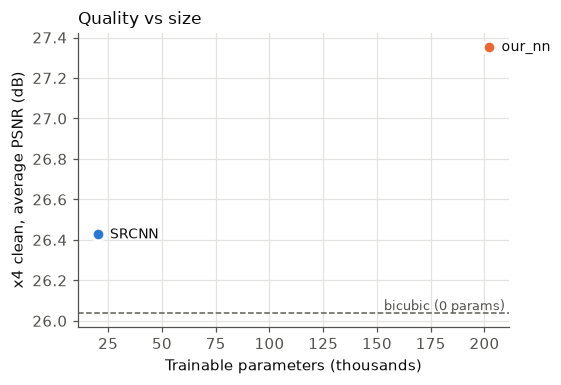

In [25]:
size = main[main.setting == "x4 clean"].groupby("model").agg(params=("param_count", "first"), psnr=("mean_psnr", "mean"),
        ssim=("mean_ssim", "mean"), time_s=("mean_inference_time_s", "mean")).loc[order]
size["time_ms"] = size.time_s * 1000
display(size.round(4))
t2 = main.groupby(["setting", "model"]).mean_inference_time_s.mean().unstack().T.loc[order] * 1000
print("Mean inference time per image (ms), by setting"); display(t2.round(2))
nn_ds = main[(main.model.isin(["srcnn", "our_nn"])) & (main.setting == "x4 clean")].pivot(index="model", columns="dataset", values="mean_inference_time_s")[DS] * 1000
print("Learned models, x4 clean, ms per image by dataset (image size matters):"); display(nn_ds.round(1))
fig, ax = plt.subplots(figsize=(5.2, 3.6))
for m in ["srcnn", "our_nn"]:
    ax.scatter(size.loc[m, "params"] / 1e3, size.loc[m, "psnr"], s=70, color=COL[m], edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(LBL[m], (size.loc[m, "params"] / 1e3, size.loc[m, "psnr"]), xytext=(8, -3), textcoords="offset points", fontsize=9)
ax.axhline(size.loc["bicubic", "psnr"], color=COL["bicubic"], ls="--", lw=1); ax.text(ax.get_xlim()[1], size.loc["bicubic", "psnr"], "bicubic (0 params) ", ha="right", va="bottom", fontsize=8.5, color=INK2)
ax.set_xlabel("Trainable parameters (thousands)"); ax.set_ylabel("x4 clean, average PSNR (dB)"); ax.set_title("Quality vs size", loc="left", fontsize=11)
fig.tight_layout(); save(fig, "extra_params_vs_psnr.png"); plt.show()

## 8. Per-image analysis (optional, needs `results/<experiment>/metrics.csv`)
Averages hide whether a gain is consistent. If the per-image files exist, this counts on how many images our_nn beats SRCNN and bicubic, and gives a paired 95% interval of the difference.

In [26]:
def load_metrics(exp):
    for f in [RESULTS_DIR / exp / "metrics.csv", RESULTS_DIR / exp / "per_image_metrics.csv"]:
        if f.exists(): return pd.read_csv(f)
    hits = glob.glob(str(RESULTS_DIR / exp / "*.csv")); 
    hits = [h for h in hits if "train_log" not in h and "summary" not in h]
    return pd.read_csv(hits[0]) if hits else None
def paired(setting_prefix, exp_nn, exp_srcnn, exp_base):
    a, b, c = load_metrics(exp_nn), load_metrics(exp_srcnn), load_metrics(exp_base)
    if a is None or b is None or c is None: print("per-image files not found for", setting_prefix); return
    for d in (a, b, c):
        d.columns = [x.lower() for x in d.columns]
    key = [k for k in ("dataset", "image", "name", "filename") if k in a.columns]
    pcol = next(k for k in a.columns if "psnr" in k)
    a = a[a.get("model", "our_nn") == "our_nn"] if "model" in a.columns else a
    b = b[b["model"] == "srcnn"] if "model" in b.columns else b
    c = c[c["model"] == "bicubic"] if "model" in c.columns else c
    m = a.merge(b, on=key, suffixes=("", "_s")).merge(c, on=key, suffixes=("", "_b"))
    d_s, d_b = m[pcol] - m[pcol + "_s"], m[pcol] - m[pcol + "_b"]
    for nm, d in (("our_nn - SRCNN", d_s), ("our_nn - bicubic", d_b)):
        se = d.std(ddof=1) / np.sqrt(len(d))
        print(f"{setting_prefix} {nm}: mean {d.mean():+.3f} dB, 95% CI [{d.mean()-1.96*se:+.3f}, {d.mean()+1.96*se:+.3f}], better on {(d>0).sum()}/{len(d)} images")
for s, e_nn, e_sr, e_b in [("x4 clean", "our_nn_x4_clean", "srcnn_x4_clean", "baselines_x4_clean"),
                           ("x2 clean", "our_nn_x2_clean", "srcnn_x2_clean", "baselines_x2_clean"),
                           ("x4 noise15", "our_nn_x4_noise15", "srcnn_x4_noise15", "baselines_x4_noise15")]:
    try: paired(s, e_nn, e_sr, e_b)
    except Exception as ex: print("skipped", s, "->", type(ex).__name__, ex)

x4 clean our_nn - SRCNN: mean +0.722 dB, 95% CI [+0.655, +0.789], better on 219/219 images
x4 clean our_nn - bicubic: mean +1.048 dB, 95% CI [+0.960, +1.137], better on 219/219 images
x2 clean our_nn - SRCNN: mean +2.039 dB, 95% CI [+1.882, +2.195], better on 219/219 images
x2 clean our_nn - bicubic: mean +2.193 dB, 95% CI [+2.031, +2.355], better on 219/219 images
x4 noise15 our_nn - SRCNN: mean +0.325 dB, 95% CI [+0.300, +0.351], better on 219/219 images
x4 noise15 our_nn - bicubic: mean +0.939 dB, 95% CI [+0.853, +1.026], better on 219/219 images


## 9. Figure 4 - qualitative comparison (optional, needs saved sample images)
Looks for `results/<experiment>/samples/<dataset>/<image>_<model>_sr.png` (plus `_hr.png` / `_lr.png` if saved). Set `PICK` to choose the image and `BOX` to choose the crop (x, y, size in HR pixels). If samples are missing the cell prints what it found and skips.

our_nn sample files found: 40 ['..\\results\\our_nn_x4_clean\\samples\\BSD100\\img_001_SRF_4_HR_our_nn_sr.png', '..\\results\\our_nn_x4_clean\\samples\\BSD100\\img_002_SRF_4_HR_our_nn_sr.png', '..\\results\\our_nn_x4_clean\\samples\\BSD100\\img_003_SRF_4_HR_our_nn_sr.png']
saved report_figures\fig4_qualitative.png


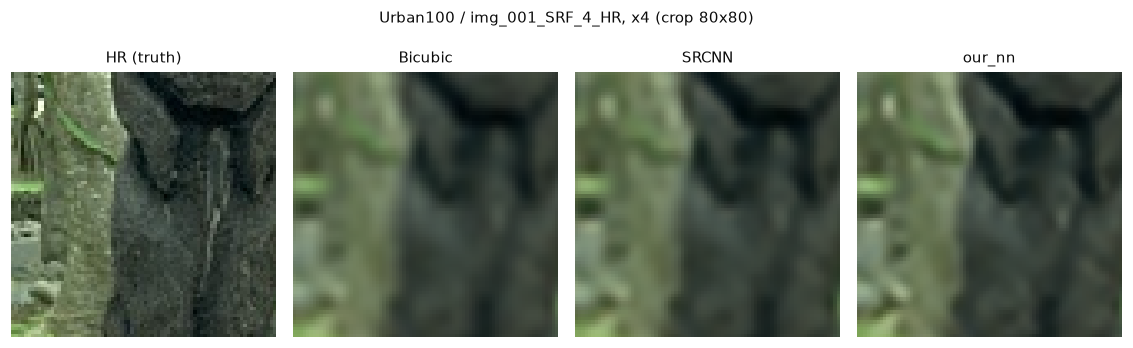

In [27]:
from PIL import Image
EXP_FOR = {"Bicubic": ("baselines_x4_clean", "bicubic"), "SRCNN": ("srcnn_x4_clean", "srcnn"), "our_nn": ("our_nn_x4_clean", "our_nn")}
DATASET, PICK, BOX = "Urban100", None, None     # PICK=None -> first image found; BOX=(x, y, size) or None for a centre crop
def find(exp, model, tag):
    base = RESULTS_DIR / exp / "samples"
    return sorted(glob.glob(str(base / "**" / f"*_{model}_{tag}.png"), recursive=True)) + sorted(glob.glob(str(base / "**" / f"*{model}*.png"), recursive=True))
sr_files = find("our_nn_x4_clean", "our_nn", "sr")
print("our_nn sample files found:", len(sr_files), sr_files[:3])
if sr_files:
    stems = [Path(f).name.rsplit("_our_nn", 1)[0] for f in sr_files]
    stem = PICK or stems[0]
    def grab(exp, model, tag="sr"):
        c = [f for f in find(exp, model, tag) if Path(f).name.startswith(stem)]
        return Image.open(c[0]).convert("RGB") if c else None
    hr_c = [f for f in glob.glob(str(RESULTS_DIR / "*" / "samples" / "**" / f"{stem}*_hr.png"), recursive=True)]
    panels = {"HR (truth)": Image.open(hr_c[0]).convert("RGB") if hr_c else None}
    for k, (e, m) in EXP_FOR.items(): panels[k] = grab(e, m)
    panels = {k: v for k, v in panels.items() if v is not None}
    ref = panels.get("our_nn") or next(iter(panels.values()))
    W, H = ref.size; s = BOX[2] if BOX else min(W, H) // 4
    x0, y0 = (BOX[0], BOX[1]) if BOX else ((W - s) // 2, (H - s) // 2)
    fig, axes = plt.subplots(1, len(panels), figsize=(2.6 * len(panels), 3.1))
    for ax, (k, im) in zip(np.atleast_1d(axes), panels.items()):
        ax.imshow(im.crop((x0, y0, x0 + s, y0 + s)), interpolation="nearest"); ax.set_title(k, fontsize=10); ax.axis("off")
    fig.suptitle(f"{DATASET} / {stem}, x4 (crop {s}x{s})", fontsize=10, y=1.02); fig.tight_layout(); save(fig, "fig4_qualitative.png"); plt.show()
else:
    print("No sample images found. Re-run evaluation with evaluation.save_samples>0, or point RESULTS_DIR at the folder with the results.")

our_nn sample files found: 40 ['..\\results\\our_nn_x4_clean\\samples\\BSD100\\img_001_SRF_4_HR_our_nn_sr.png', '..\\results\\our_nn_x4_clean\\samples\\BSD100\\img_002_SRF_4_HR_our_nn_sr.png', '..\\results\\our_nn_x4_clean\\samples\\BSD100\\img_003_SRF_4_HR_our_nn_sr.png']
saved report_figures\fig4_qualitative.png


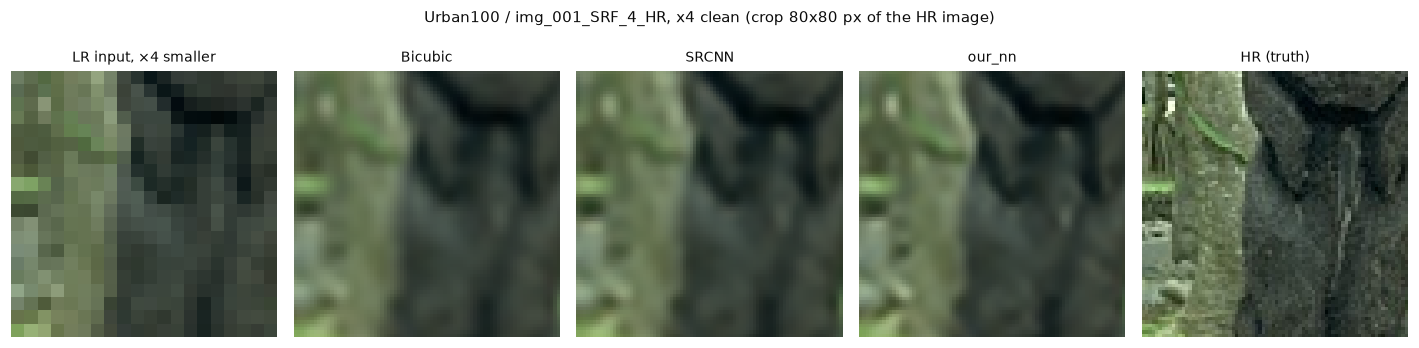

In [28]:
from PIL import Image
SETTING = "x4_clean"          # "x4_clean" or "x4_noise15"
SCALE = 4
SIGMA = 15 if "noise" in SETTING else 0          # noise std on the 0-255 scale
EXP_FOR = {"Bicubic": (f"baselines_{SETTING}", "bicubic"),
           "SRCNN":   (f"srcnn_{SETTING}", "srcnn"),
           "our_nn":  (f"our_nn_{SETTING}", "our_nn")}
DATASET, PICK, BOX = "Urban100", None, None   # PICK=None -> first image found; BOX=(x, y, size) in HR pixels, None -> centre crop

def find(exp, model, tag):
    base = RESULTS_DIR / exp / "samples"
    return sorted(glob.glob(str(base / "**" / f"*_{model}_{tag}.png"), recursive=True)) + \
           sorted(glob.glob(str(base / "**" / f"*{model}*.png"), recursive=True))

def degrade(hr_img, scale=SCALE, sigma=SIGMA, seed=0):
    """HR -> LR the same way as the benchmark: bicubic downscale, then Gaussian noise (0-255 scale), 8-bit."""
    w, h = hr_img.width - hr_img.width % scale, hr_img.height - hr_img.height % scale
    lr = hr_img.crop((0, 0, w, h)).resize((w // scale, h // scale), Image.BICUBIC)
    a = np.asarray(lr, dtype=np.float32)
    if sigma > 0:
        a = a + np.random.default_rng(seed).normal(0, sigma, a.shape)
    return Image.fromarray(np.clip(np.round(a), 0, 255).astype(np.uint8))

sr_files = find(f"our_nn_{SETTING}", "our_nn", "sr")
print("our_nn sample files found:", len(sr_files), sr_files[:3])
if sr_files:
    stems = [Path(f).name.rsplit("_our_nn", 1)[0] for f in sr_files]
    stem = PICK or stems[0]

    def grab(exp, model, tag="sr"):
        c = [f for f in find(exp, model, tag) if Path(f).name.startswith(stem)]
        return Image.open(c[0]).convert("RGB") if c else None

    hr_c = glob.glob(str(RESULTS_DIR / "*" / "samples" / "**" / f"{stem}*_hr.png"), recursive=True)
    hr = Image.open(hr_c[0]).convert("RGB") if hr_c else None
    assert hr is not None, "HR sample image not found - the degraded input is made from it"
    lr = degrade(hr)                                   # degraded input, made right here
    sr = {k: grab(e, m) for k, (e, m) in EXP_FOR.items()}
    ref = sr.get("our_nn") or hr
    W, H = ref.size
    s = BOX[2] if BOX else min(W, H) // 4
    s -= s % SCALE
    x0, y0 = (BOX[0], BOX[1]) if BOX else ((W - s) // 2, (H - s) // 2)
    x0 -= x0 % SCALE; y0 -= y0 % SCALE

    lr_title = "LR input" + (f" (noise σ={SIGMA})" if SIGMA else "") + f", ×{SCALE} smaller"
    l = lr.crop((x0 // SCALE, y0 // SCALE, (x0 + s) // SCALE, (y0 + s) // SCALE))
    panels = {lr_title: l.resize((s, s), Image.NEAREST)}   # same region, pixels repeated (no smoothing)
    for k, v in sr.items():
        if v is not None: panels[k] = v.crop((x0, y0, x0 + s, y0 + s))
    panels["HR (truth)"] = hr.crop((x0, y0, x0 + s, y0 + s))

    fig, axes = plt.subplots(1, len(panels), figsize=(2.6 * len(panels), 3.1))
    for ax, (k, im) in zip(np.atleast_1d(axes), panels.items()):
        ax.imshow(im, interpolation="nearest"); ax.set_title(k, fontsize=9); ax.axis("off")
    fig.suptitle(f"{DATASET} / {stem}, {SETTING.replace('_', ' ')} (crop {s}x{s} px of the HR image)", fontsize=10, y=1.02)
    fig.tight_layout(); save(fig, "fig4_qualitative.png"); plt.show()
else:
    print("No sample images found. Re-run evaluation with evaluation.save_samples>0, or point RESULTS_DIR at the folder with the results.")

## 10. Figure 1 - architecture block diagram

saved report_figures\fig1_architecture.png


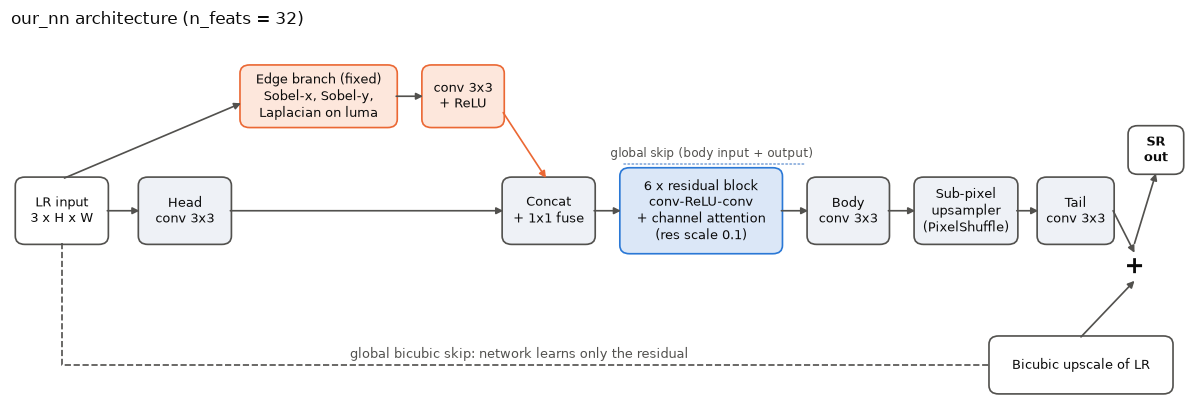

In [29]:
fig, ax = plt.subplots(figsize=(11, 3.9)); ax.set_xlim(0, 22); ax.set_ylim(0, 8); ax.axis("off")
def box(x, y, w, h, t, fc="#eef1f6", ec=INK2, fs=8.5, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.18", fc=fc, ec=ec, lw=1.1))
    ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal")
def arrow(p, q, c=INK2, ls="-"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=9, lw=1.1, color=c, linestyle=ls, shrinkA=0, shrinkB=0))
yc = 4.2
box(0.1, yc - 0.7, 1.7, 1.4, "LR input\n3 x H x W", fc="#ffffff")
box(2.4, yc - 0.7, 1.7, 1.4, "Head\nconv 3x3")
box(4.3, 6.0, 2.9, 1.3, "Edge branch (fixed)\nSobel-x, Sobel-y,\nLaplacian on luma", fc="#fde7dc", ec="#eb6834")
box(7.7, 6.0, 1.5, 1.3, "conv 3x3\n+ ReLU", fc="#fde7dc", ec="#eb6834")
box(9.2, yc - 0.7, 1.7, 1.4, "Concat\n+ 1x1 fuse")
box(11.4, yc - 0.9, 3.0, 1.8, "6 x residual block\nconv-ReLU-conv\n+ channel attention\n(res scale 0.1)", fc="#dbe7f7", ec="#2a78d6")
box(14.9, yc - 0.7, 1.5, 1.4, "Body\nconv 3x3")
box(16.9, yc - 0.7, 1.9, 1.4, "Sub-pixel\nupsampler\n(PixelShuffle)")
box(19.2, yc - 0.7, 1.4, 1.4, "Tail\nconv 3x3")
box(18.3, 0.3, 3.4, 1.2, "Bicubic upscale of LR", fc="#ffffff")
box(20.9, 2.3, 1.0, 0.0, "", fc="none", ec="none")
ax.text(21.0, 3.0, "+", fontsize=16, ha="center", va="center", fontweight="bold")
box(20.9, 5.0, 1.0, 1.0, "SR\nout", fc="#ffffff", bold=True)
for p, q in [((1.8, yc), (2.4, yc)), ((4.1, yc), (9.2, yc)), ((10.9, yc), (11.4, yc)), ((14.4, yc), (14.9, yc)),
             ((16.4, yc), (16.9, yc)), ((18.8, yc), (19.2, yc))]: arrow(p, q)
arrow((1.0, 4.9), (4.3, 6.5)); arrow((7.2, 6.65), (7.7, 6.65)); arrow((9.2, 6.3), (10.0, 4.9), c="#eb6834")
arrow((20.6, yc), (21.0, 3.3)); arrow((20.0, 1.5), (21.0, 2.7)); arrow((21.0, 3.5), (21.4, 5.0))
ax.plot([0.95, 0.95, 18.3], [yc - 0.7, 0.9, 0.9], color=INK2, lw=1.1, ls="--")
ax.text(9.5, 1.05, "global bicubic skip: network learns only the residual", ha="center", fontsize=8.5, color=INK2)
ax.annotate("", xy=(14.9, yc + 1.0), xytext=(11.4, yc + 1.0), arrowprops=dict(arrowstyle="-", color="#7aa2d8", ls=":"))
ax.text(13.1, yc + 1.15, "global skip (body input + output)", ha="center", fontsize=8, color=INK2)
ax.set_title("our_nn architecture (n_feats = 32)", loc="left", fontsize=11)
fig.tight_layout(); save(fig, "fig1_architecture.png"); plt.show()

## 11. Numbers to quote in the report (printed so you can check the text against them)

In [30]:
for s in ["x4 clean", "x2 clean", "x4 noise15"]:
    t = TABLES[(s, "mean_psnr")]["Average"]; u = TABLES[(s, "mean_ssim")]["Average"]
    print(f"[{s}] PSNR avg:", t.round(2).to_dict()); print(f"[{s}] SSIM avg:", u.round(4).to_dict())
print("params:", main.groupby("model").param_count.first().to_dict())
print("\nSaved figures:", sorted(p.name for p in FIG.glob("*.png")))

[x4 clean] PSNR avg: {'nearest': 24.55, 'bilinear': 25.33, 'bicubic': 26.04, 'lanczos': 26.15, 'srcnn': 26.43, 'our_nn': 27.36}
[x4 clean] SSIM avg: {'nearest': 0.6598, 'bilinear': 0.6885, 'bicubic': 0.7141, 'lanczos': 0.7181, 'srcnn': 0.7304, 'our_nn': 0.764}
[x2 clean] PSNR avg: {'nearest': 28.37, 'bilinear': 29.04, 'bicubic': 30.34, 'lanczos': 30.57, 'srcnn': 30.49, 'our_nn': 32.74}
[x2 clean] SSIM avg: {'nearest': 0.8482, 'bilinear': 0.8431, 'bicubic': 0.876, 'lanczos': 0.8805, 'srcnn': 0.8774, 'our_nn': 0.9144}
[x4 noise15] PSNR avg: {'nearest': 23.14, 'bilinear': 24.46, 'bicubic': 24.53, 'lanczos': 24.5, 'srcnn': 25.26, 'our_nn': 25.63}
[x4 noise15] SSIM avg: {'nearest': 0.5147, 'bilinear': 0.6236, 'bicubic': 0.6079, 'lanczos': 0.6032, 'srcnn': 0.6725, 'our_nn': 0.6889}
params: {'bicubic': 0, 'bilinear': 0, 'lanczos': 0, 'nearest': 0, 'our_nn': 165267, 'srcnn': 20099}

Saved figures: ['extra_params_vs_psnr.png', 'fig1_architecture.png', 'fig2_results.png', 'fig3_ablation.png', 'f